# Task 4 — Engineered screenshot EDA

Verify → inspect → extract → save. Feature families: RGB spatial averages, HSV histograms, HOG edge orientation, and local binary pattern texture. HOG and LBP follow [scikit-image HOG](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html) and [LBP API](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.local_binary_pattern). All features are deterministic per image; scaling/selection happens only after the validation split in the model notebook. These are common classical image descriptors, not a claim that they are optimal for game screenshots.

This review includes feature-family summaries, per-class appearance, top descriptive class contrasts, and train/test distribution checks.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"
RAW = SRC / "task4" / "data" / "raw"
from src.pipeline.random_seed import set_seed
SEED = set_seed()
import json
import numpy as np
import pandas as pd
from IPython.display import display

from src.task4.image_features import extract_image
from src.pipeline.save_data import save_data

# Verify

In [2]:
train_raw = pd.read_csv(RAW / "train.csv")
test_raw = pd.read_csv(RAW / "test-outdate-12-11-2026.csv")
assert train_raw.columns.tolist() == test_raw.columns.tolist() == ["id", "class"]
assert train_raw["id"].is_unique and test_raw["id"].is_unique
assert not train_raw["id"].isna().any() and not test_raw["id"].isna().any()
assert train_raw["class"].notna().all() and test_raw["class"].isna().all()
assert not (set(train_raw.id) & set(test_raw.id))
display(train_raw["class"].value_counts().to_frame("train_count"))
print("Train/test rows:", len(train_raw), len(test_raw))
print("Missing train images:", sum(not (RAW / "train" / f"{x}.jpg").is_file() for x in train_raw.id))
print("Missing test images:", sum(not (RAW / "test" / f"{x}.jpg").is_file() for x in test_raw.id))


,train_count
class,
7-11k,12429
pube,5926
freefried,5596
fiveN,4407
roblock,3188


Train/test rows: 31546 25889


Missing train images: 0


Missing test images: 0


# Feature extraction

In [3]:
def make_frame(manifest, split):
    first = extract_image(RAW / split / f"{manifest.iloc[0]['id']}.jpg", engineered=True)
    numeric_cols = [c for c in first if c != "image_sha256"]
    values = np.empty((len(manifest), len(numeric_cols)), dtype=np.float32)
    hashes = []
    for index, row in enumerate(manifest.itertuples(index=False)):
        item = extract_image(RAW / split / f"{row.id}.jpg", engineered=True)
        values[index] = [item[c] for c in numeric_cols]
        hashes.append(item["image_sha256"])
        if (index + 1) % 5000 == 0:
            print(split, index + 1, "images")
    frame = pd.DataFrame(values, columns=numeric_cols)
    frame.insert(0, "image_sha256", hashes)
    frame.insert(0, "class", manifest["class"].to_numpy())
    frame.insert(0, "id", manifest["id"].to_numpy())
    return frame

train_df = make_frame(train_raw, "train")
test_df = make_frame(test_raw, "test")

train 5000 images


train 10000 images


train 15000 images


train 20000 images


train 25000 images


train 30000 images


test 5000 images


test 10000 images


test 15000 images


test 20000 images


test 25000 images


# Review feature quality and leakage

In [4]:
feature_cols = [c for c in test_df if c not in ["id", "class", "image_sha256", "width", "height"]]
assert train_df.columns.tolist() == test_df.columns.tolist()
assert np.isfinite(train_df[feature_cols].to_numpy()).all()
assert np.isfinite(test_df[feature_cols].to_numpy()).all()
assert not (set(train_df.image_sha256) & set(test_df.image_sha256))
groups = train_df.groupby("image_sha256")["class"].nunique()
assert groups.eq(1).all(), "Identical images with different labels need review"
print("Features:", len(feature_cols), "exact duplicate groups:", int((train_df.image_sha256.value_counts()>1).sum()))
display(train_df[feature_cols].describe().loc[["mean", "std", "min", "max"], feature_cols[:12]])

Features: 1228 exact duplicate groups: 0


,px_000,px_001,px_002,px_003,px_004,px_005,px_006,px_007,px_008,px_009,px_010,px_011
mean,0.296086,0.296499,0.296166,0.317152,0.317577,0.317805,0.365935,0.365921,0.366332,0.444423,0.444037,0.444799
std,0.284006,0.286254,0.284734,0.280412,0.282937,0.281659,0.272922,0.274845,0.273335,0.282684,0.284328,0.282702
min,0.011765,0.011765,0.011765,0.011765,0.011765,0.011765,0.011765,0.011765,0.011765,0.011765,0.011765,0.011765
max,0.980392,0.984314,0.984314,0.984314,0.984314,0.988235,0.984314,0.984314,0.984314,0.984314,0.984314,0.984314


## What the engineered features show

Summarize feature families, missing or constant values, and color/texture differences by game. The class-contrast table uses **Train labels only** for description; it is not fitted preprocessing or feature selection for the model notebook.

In [5]:
families = {
    "pixels": [c for c in feature_cols if c.startswith("px_")],
    "spatial_RGB_and_stats": [c for c in feature_cols if c.startswith(("r_", "g_", "b_"))],
    "HSV_histogram": [c for c in feature_cols if c.endswith("_hist_00") or "_hist_" in c],
    "HOG_edges": [c for c in feature_cols if c.startswith("hog_")],
    "LBP_texture": [c for c in feature_cols if c.startswith("lbp_")],
}
display(pd.DataFrame({"family": list(families), "features": [len(v) for v in families.values()]}))
quality = pd.DataFrame({"missing_train": train_df[feature_cols].isna().sum(),
                        "missing_test": test_df[feature_cols].isna().sum(),
                        "train_unique": train_df[feature_cols].nunique()})
print("Missing values:", int(quality[["missing_train", "missing_test"]].sum().sum()))
print("Constant train features:", int(quality.train_unique.le(1).sum()))
display(quality.loc[quality.train_unique.le(1)].head(20))
class_appearance = train_df.groupby("class")[["r_mean", "g_mean", "b_mean"]].mean()
class_appearance["brightness"] = class_appearance.mean(axis=1)
display(class_appearance.round(3))

,family,features
0,pixels,384
1,spatial_RGB_and_stats,30
2,HSV_histogram,48
3,HOG_edges,756
4,LBP_texture,10


Missing values: 0
Constant train features: 0


,missing_train,missing_test,train_unique


,r_mean,g_mean,b_mean,brightness
class,,,,
7-11k,0.476,0.478,0.477,0.477
fiveN,0.414,0.413,0.413,0.413
freefried,0.434,0.436,0.433,0.434
pube,0.427,0.427,0.430,0.428
roblock,0.471,0.463,0.468,0.467


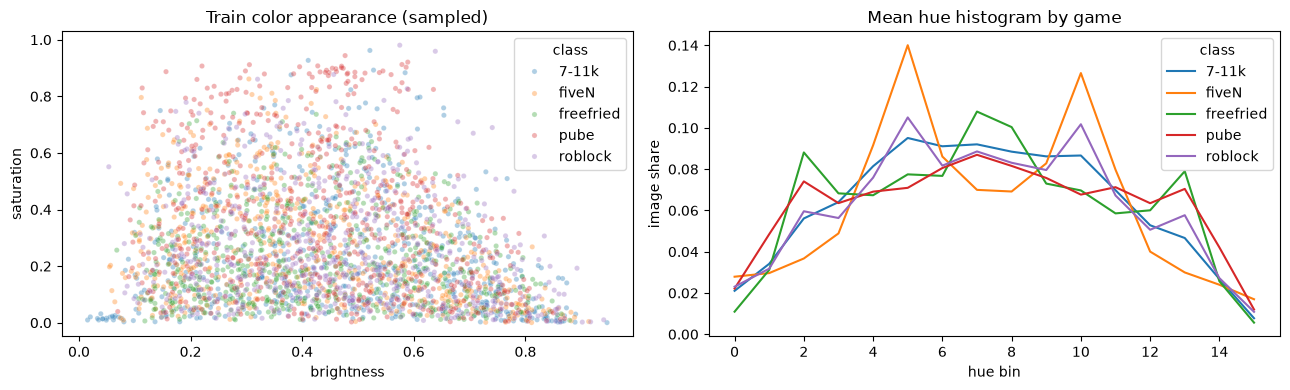

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
sampled = train_df.groupby("class", group_keys=False).sample(n=600, random_state=SEED)
sampled = sampled.assign(brightness=sampled[["r_mean", "g_mean", "b_mean"]].mean(axis=1),
                         saturation=1 - sampled[["r_mean", "g_mean", "b_mean"]].min(axis=1) /
                         sampled[["r_mean", "g_mean", "b_mean"]].max(axis=1).clip(lower=1e-6))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=sampled, x="brightness", y="saturation", hue="class", alpha=.35, s=14, ax=axes[0])
axes[0].set_title("Train color appearance (sampled)")
hue_cols = [f"h_hist_{i:02d}" for i in range(16)]
hue_by_class = train_df.groupby("class")[hue_cols].mean().T
hue_by_class.index = range(16)
hue_by_class.plot(ax=axes[1])
axes[1].set(title="Mean hue histogram by game", xlabel="hue bin", ylabel="image share")
plt.tight_layout()

## Class contrasts and train/test comparison

Between-class variance highlights descriptors worth inspecting in the next round. Compare selected image statistics across Train and Test to flag a shift; Test labels remain unknown and Test is not used for fitting.

,between_class_variance_ratio
lbp_02,0.106746
s_hist_14,0.096879
hog_621,0.087873
hog_620,0.080456
h_hist_05,0.078015
hog_386,0.076918
lbp_06,0.076573
hog_648,0.075604
hog_593,0.075056
hog_630,0.073631


,train_mean,test_mean,train_std,standardized_mean_gap
g_mean,0.450,0.412,0.221,0.173
r_mean,0.450,0.413,0.220,0.170
b_mean,0.450,0.413,0.220,0.169
h_hist_08,0.086,0.079,0.075,0.092
lbp_08,0.085,0.087,0.021,0.089
h_hist_15,0.010,0.013,0.041,0.082
lbp_01,0.087,0.086,0.011,0.079
h_hist_07,0.090,0.084,0.080,0.075
h_hist_14,0.029,0.032,0.068,0.049
h_hist_03,0.062,0.059,0.068,0.046


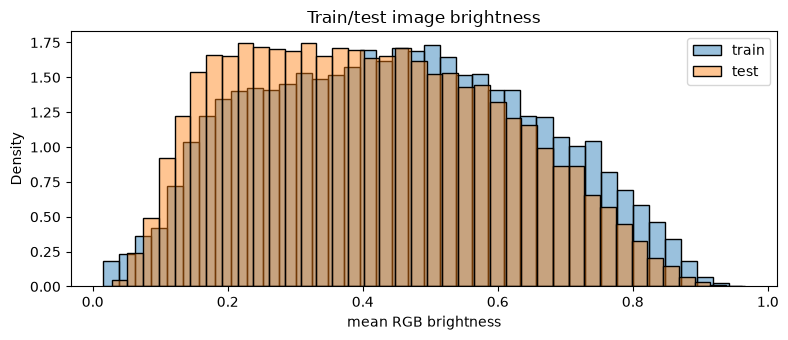

In [7]:
means = train_df.groupby("class")[feature_cols].mean()
between = means.var(axis=0)
overall = train_df[feature_cols].var(axis=0).replace(0, np.nan)
contrast = (between / overall).sort_values(ascending=False)
display(contrast.head(15).rename("between_class_variance_ratio").to_frame())
drift_cols = ["r_mean", "g_mean", "b_mean"] + [f"h_hist_{i:02d}" for i in range(16)] + [f"lbp_{i:02d}" for i in range(10)]
comparison = pd.DataFrame({"train_mean": train_df[drift_cols].mean(),
                           "test_mean": test_df[drift_cols].mean(),
                           "train_std": train_df[drift_cols].std()})
comparison["standardized_mean_gap"] = ((comparison.test_mean - comparison.train_mean).abs() /
                                        comparison.train_std.replace(0, np.nan))
display(comparison.sort_values("standardized_mean_gap", ascending=False).head(12).round(3))
fig, ax = plt.subplots(figsize=(8, 3.5))
train_brightness = train_df[["r_mean", "g_mean", "b_mean"]].mean(axis=1)
test_brightness = test_df[["r_mean", "g_mean", "b_mean"]].mean(axis=1)
sns.histplot(train_brightness, bins=40, stat="density", alpha=.45, label="train", ax=ax)
sns.histplot(test_brightness, bins=40, stat="density", alpha=.45, label="test", ax=ax)
ax.set(title="Train/test image brightness", xlabel="mean RGB brightness")
ax.legend(); plt.tight_layout()

### EDA observation

All 1,228 numeric features are finite, with no missing or constant train columns. Average RGB brightness differs between classes, but their mean channel values are close enough that color alone is unlikely to separate every screenshot. Test RGB means are about 0.037 lower than Train (roughly 0.17 Train standard deviations); track this mild shift during validation. The class-contrast table above is descriptive and never selects columns before splitting.

# Save dataset

In [8]:
data_info = save_data(task=4, name="eda_1_v1", train=train_df, test=test_df,
    card={"source": "task4/data/raw/train.csv, test-outdate-12-11-2026.csv, train/*.jpg, test/*.jpg",
          "features": "16x8 RGB pixels; spatial RGB means; 16-bin HSV histograms; 64x32 HOG; uniform LBP histogram",
          "excluded_from_models": ["id", "class", "image_sha256", "width", "height"],
          "leakage": "per-image extraction only; exact hashes checked; fit transforms on development split"})
print(json.dumps(data_info, indent=2)[:1200])

{
  "name": "eda_1_v1",
  "task": "task4",
  "created_at": "2026-11-06T05:22:56+00:00",
  "card": {
    "source": "task4/data/raw images and CSV manifests",
    "features": "16x8 RGB pixels; spatial RGB means; 16-bin HSV histograms; 64x32 HOG; uniform LBP histogram",
    "excluded_from_models": [
      "id",
      "class",
      "image_sha256",
      "width",
      "height"
    ],
    "leakage": "per-image extraction only; exact hashes checked; fit transforms on development split"
  },
  "format": "parquet",
  "splits": {
    "train": {
      "path": "task4/data/eda/eda_1_v1-train.parquet",
      "card_path": "task4/data/eda/eda_1_v1-train.json",
      "rows": 31546,
      "columns": {
        "id": "str",
        "class": "str",
        "image_sha256": "str",
        "width": "float32",
        "height": "float32",
        "px_000": "float32",
        "px_001": "float32",
        "px_002": "float32",
        "px_003": "float32",
        "px_004": "float32",
        "px_005": "float32"